# Error analysis and embeddings

This notebook inspects cached predictions, per-class metrics, confusion matrices, and penultimate-layer embeddings. It performs no inference. It uses validation artifacts for a pre-TEST preview and switches to the complete locked TEST artifact set automatically.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
import sys
ROOT = Path.cwd()
if not (ROOT / 'reports').exists(): ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))
from material_classifier.plotting import plot_confusion_matrix, plot_per_class_metrics, project_embeddings, plot_embeddings, error_gallery
from generate_report import _test_gate_diagnostics
MODELS = ('custom_cnn', 'resnet50', 'convnext_tiny', 'vit_b16')
CLASSES = ('wood', 'metal', 'stone', 'concrete', 'ceramic', 'fabric', 'leather')
test_paths = [ROOT / 'reports' / 'results' / model / 'test' / name for model in MODELS for name in ('metrics.json', 'predictions.csv', 'embeddings.npz')]
test_files_present = any(path.exists() for path in test_paths)
gate_diagnostics = _test_gate_diagnostics(ROOT)
if test_files_present and gate_diagnostics: raise RuntimeError('TEST artifacts are present but the lock/hashed-marker gate is invalid: ' + '; '.join(gate_diagnostics))
SPLIT = 'test' if test_files_present else 'val'
print('FINAL TEST RESULTS' if SPLIT == 'test' else 'VALIDATION PREVIEW ONLY - final TEST results require a valid lock and hashed completion markers.')

FINAL TEST RESULTS


,image_path,material_id,true_label,pred_label,confidence
271,dataset/test/metal/metal_15_r02.png,metal_15,metal,leather,0.950195
286,dataset/test/metal/metal_15_r17.png,metal_15,metal,leather,0.936035
276,dataset/test/metal/metal_15_r07.png,metal_15,metal,leather,0.925293
277,dataset/test/metal/metal_15_r08.png,metal_15,metal,leather,0.921875
295,dataset/test/metal/metal_15_r26.png,metal_15,metal,leather,0.916504
289,dataset/test/metal/metal_15_r20.png,metal_15,metal,leather,0.892578
284,dataset/test/metal/metal_15_r15.png,metal_15,metal,leather,0.890137
325,dataset/test/stone/stone_05_r26.png,stone_05,stone,ceramic,0.888184
291,dataset/test/metal/metal_15_r22.png,metal_15,metal,leather,0.885742
288,dataset/test/metal/metal_15_r19.png,metal_15,metal,leather,0.878906


,class,precision,recall,f1,support
0,wood,1.000000,0.733333,0.846154,60
1,metal,0.933333,0.233333,0.373333,60
2,stone,0.714286,0.500000,0.588235,60
3,concrete,1.000000,0.950000,0.974359,60
4,ceramic,0.361446,0.500000,0.419580,60
5,fabric,0.666667,0.966667,0.789116,60
6,leather,0.652174,1.000000,0.789474,60


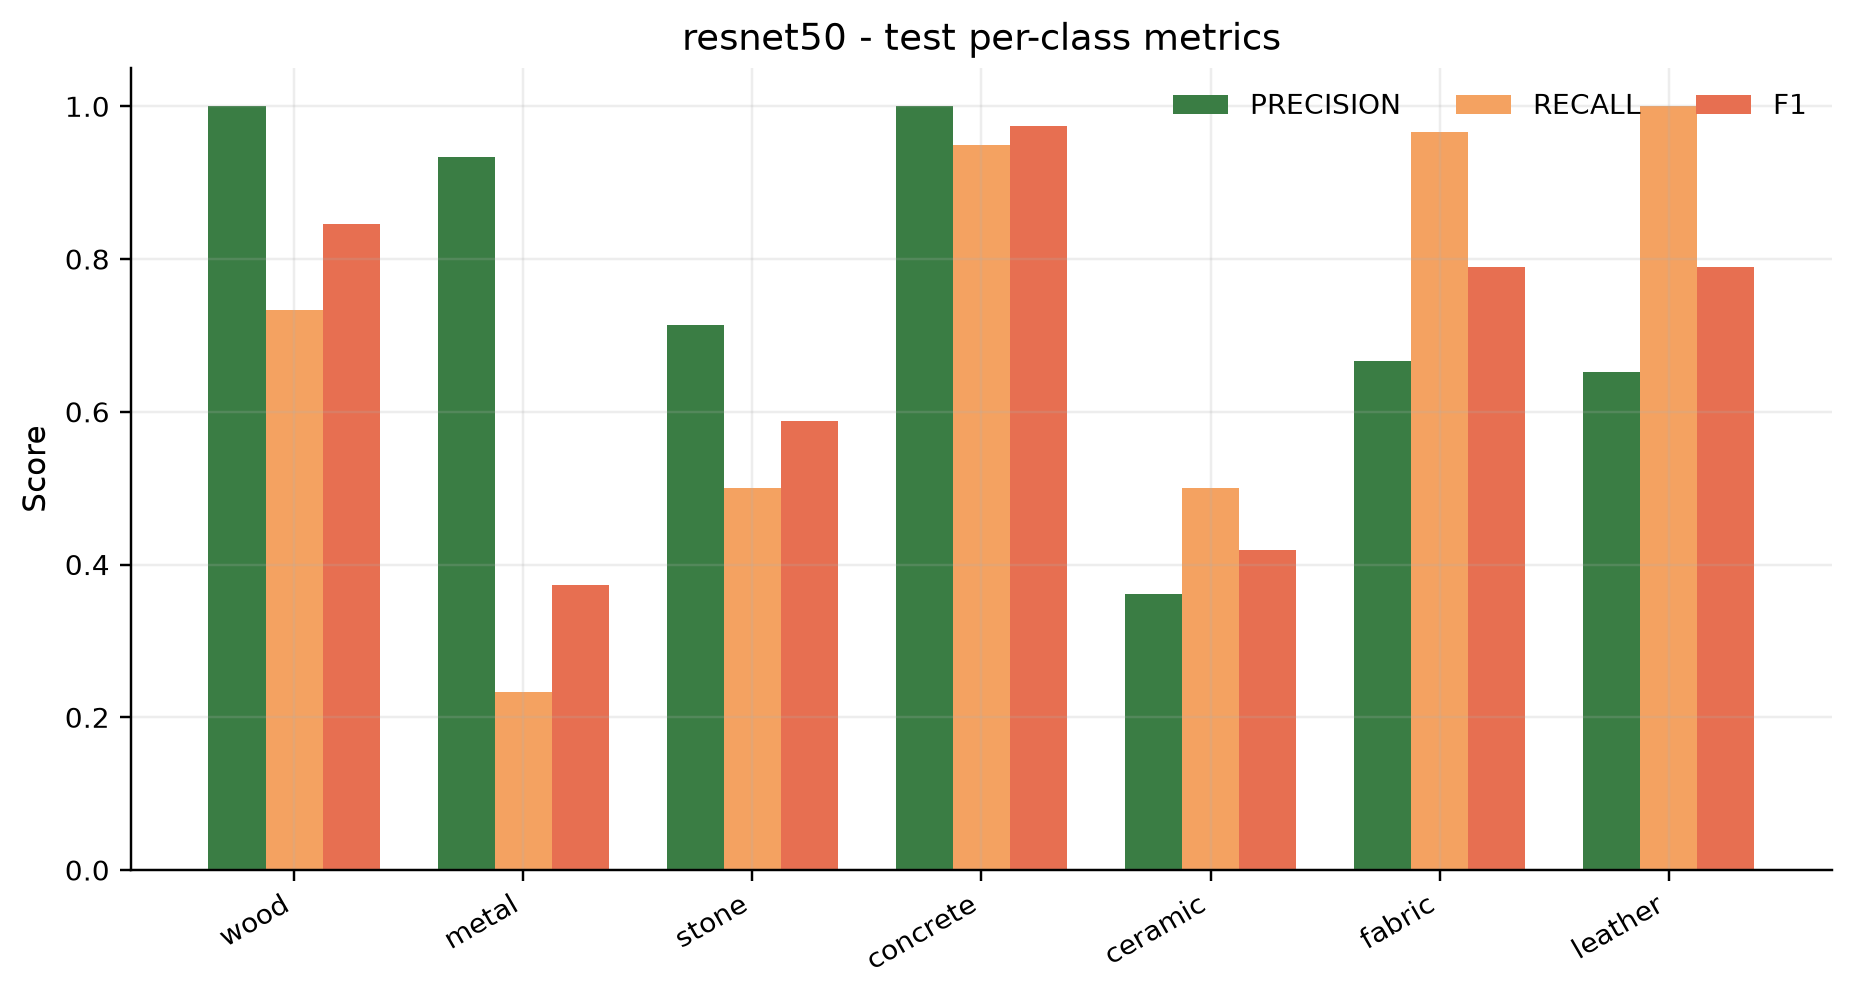

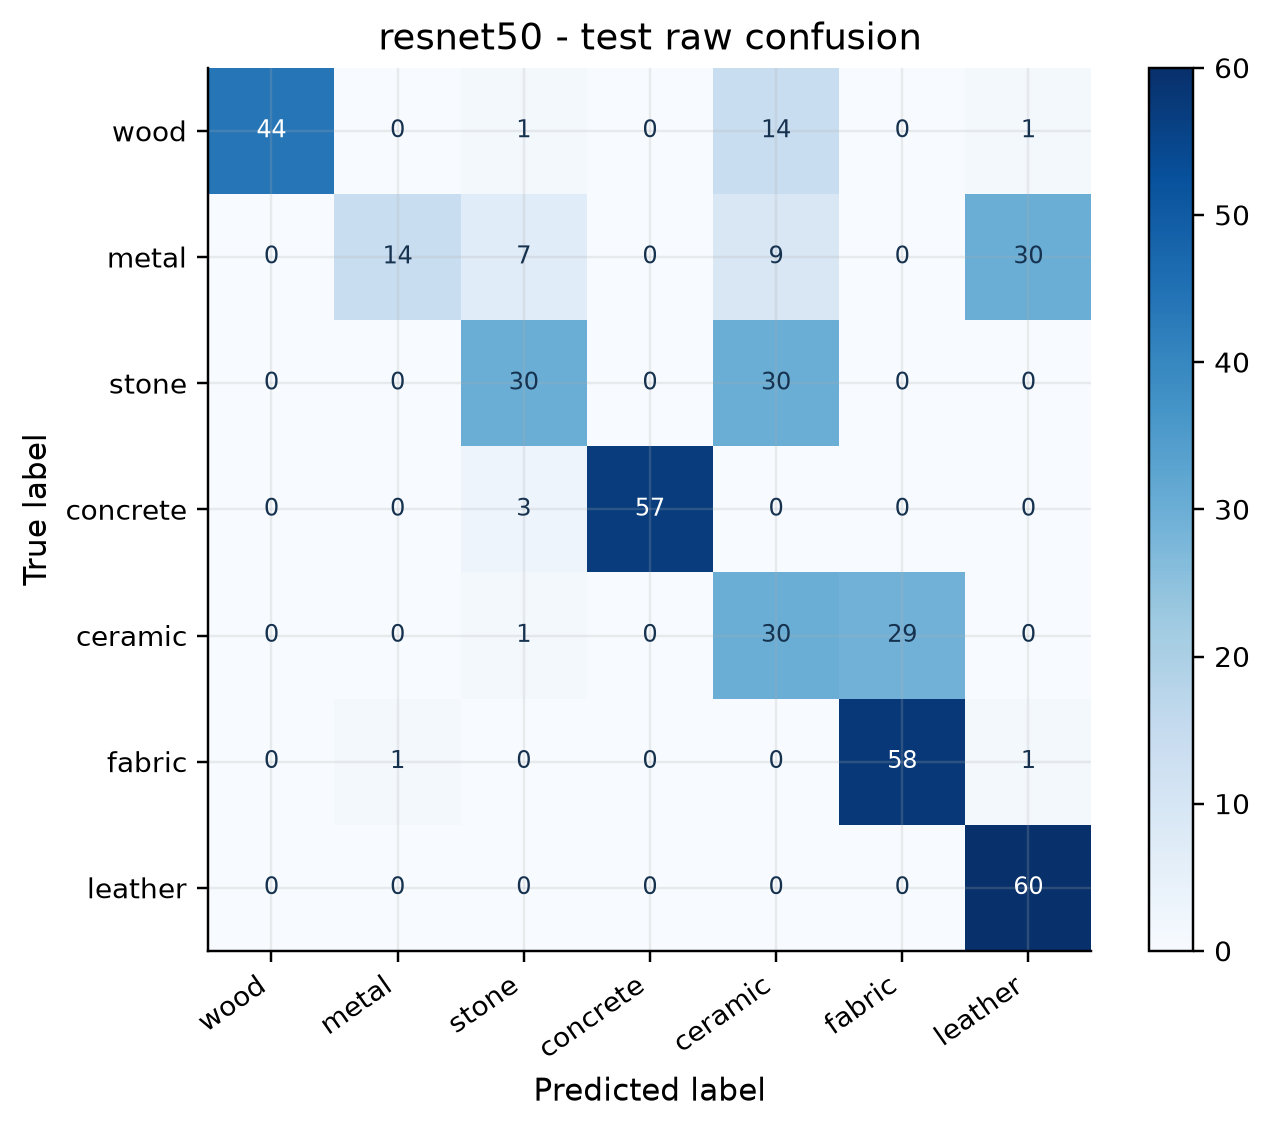

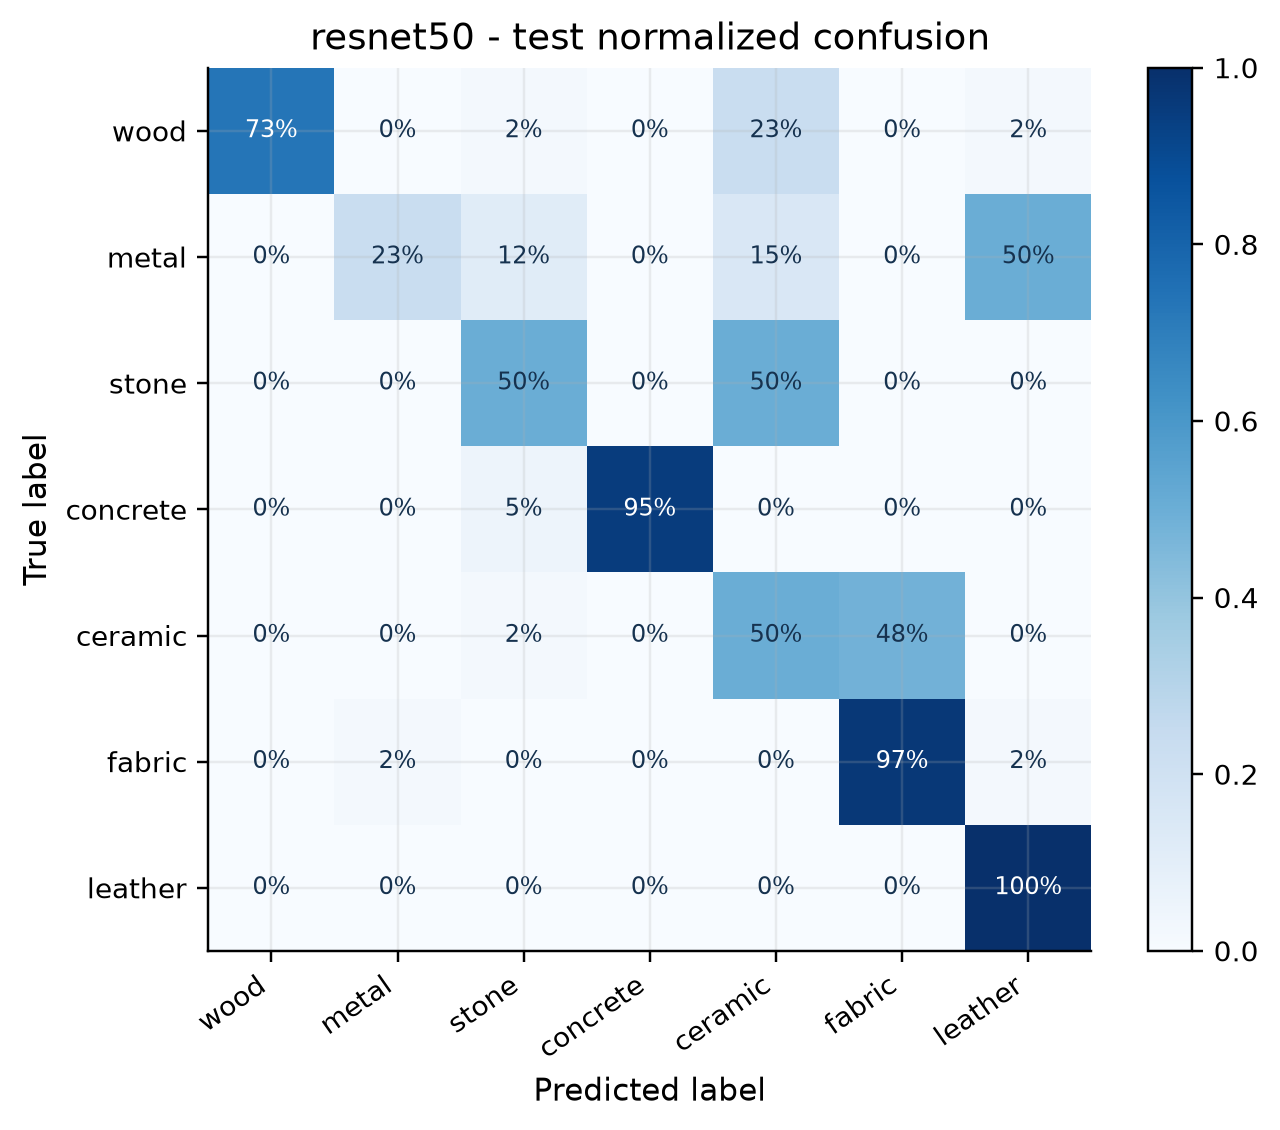

In [2]:
model = 'resnet50'
metrics_path = ROOT / 'reports' / 'results' / model / SPLIT / 'metrics.json'
predictions_path = ROOT / 'reports' / 'results' / model / SPLIT / 'predictions.csv'
if metrics_path.exists() and predictions_path.exists():
    payload = json.loads(metrics_path.read_text(encoding='utf-8'))
    predictions = pd.read_csv(predictions_path)
    errors = predictions[predictions.true_label != predictions.pred_label].sort_values('confidence', ascending=False)
    display(errors[['image_path', 'material_id', 'true_label', 'pred_label', 'confidence']].head(20))
    display(pd.DataFrame(payload.get('per_class', [])))
    per_class_output = ROOT / 'reports' / 'figures' / 'notebook_error_analysis' / f'{model}_{SPLIT}_per_class.png'
    plot_per_class_metrics(payload.get('per_class', []), per_class_output, f'{model} - {SPLIT} per-class metrics')
    display(Image(filename=str(per_class_output)))
    for kind, normalized in (('raw', False), ('normalized', True)):
        output = ROOT / 'reports' / 'figures' / 'notebook_error_analysis' / f'{model}_{SPLIT}_{kind}.png'
        plot_confusion_matrix(payload['confusion_matrix'], CLASSES, output, normalized=normalized, title=f'{model} - {SPLIT} {kind} confusion')
        display(Image(filename=str(output)))
else:
    print('No cached prediction artifact for this model/split.')

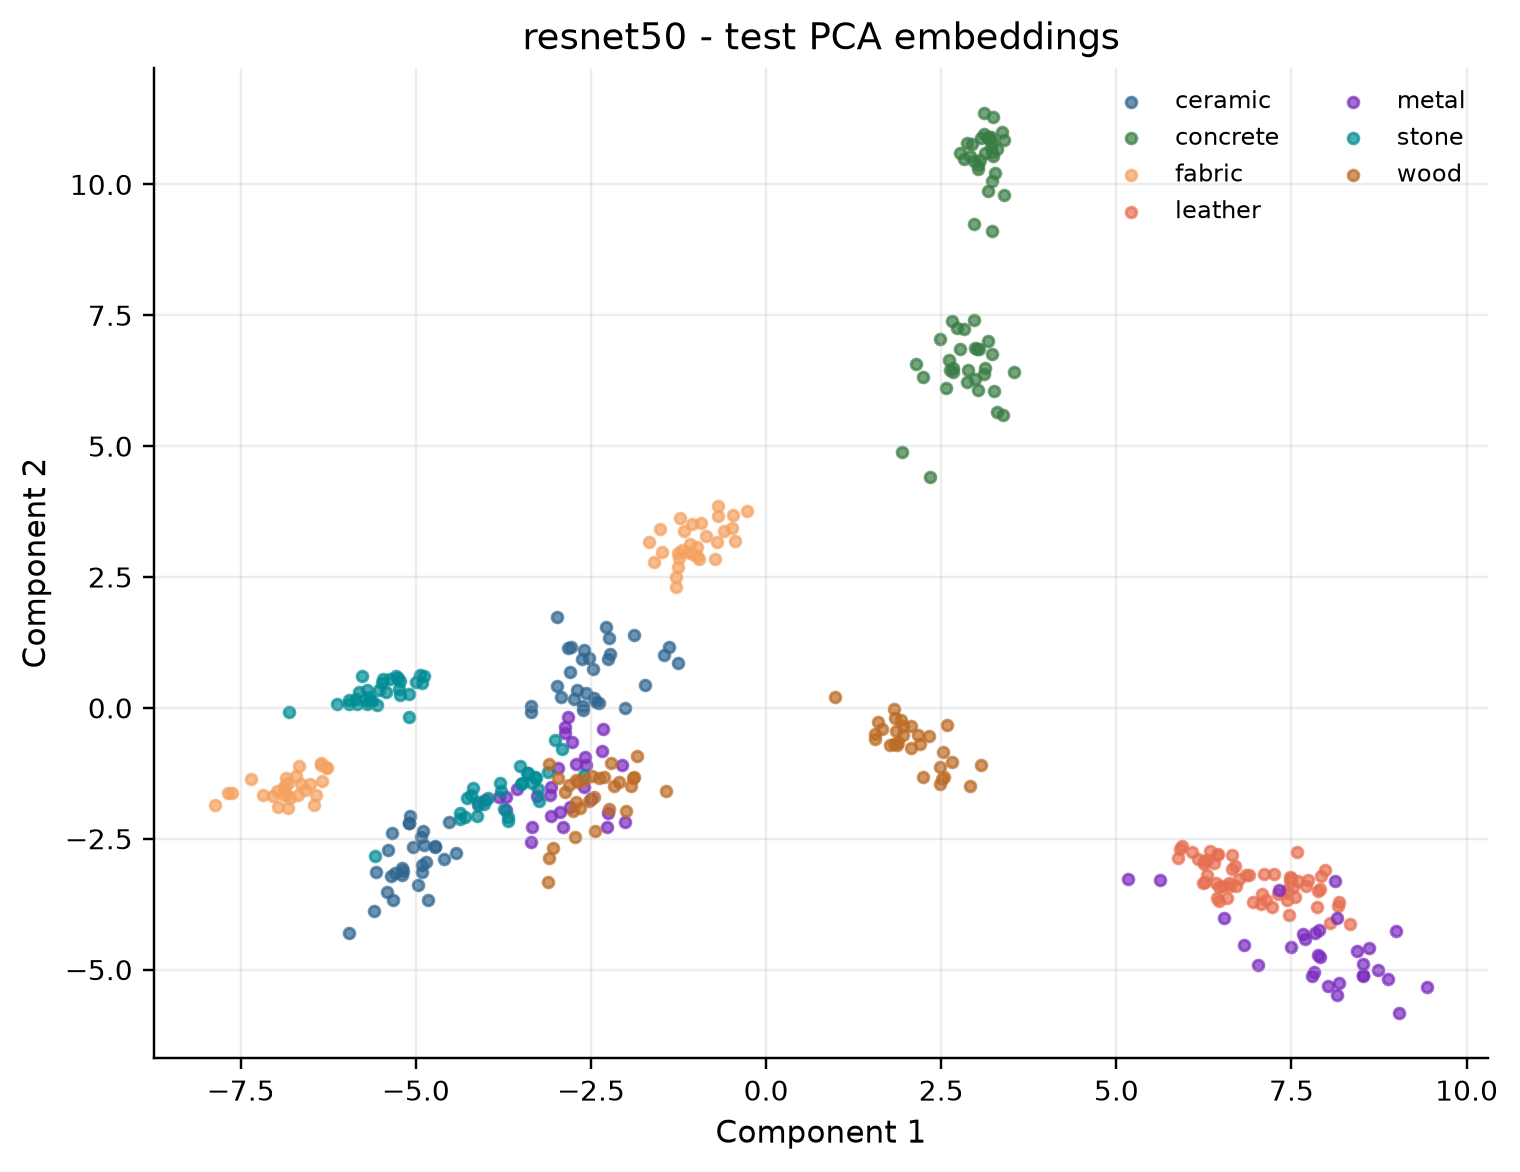

In [3]:
embedding_path = ROOT / 'reports' / 'results' / model / SPLIT / 'embeddings.npz'
if embedding_path.exists():
    points, labels, method = project_embeddings(embedding_path, 'pca', CLASSES)
    output = ROOT / 'reports' / 'figures' / 'notebook_error_analysis' / f'{model}_{SPLIT}_{method}.png'
    plot_embeddings(points, labels, output, title=f'{model} - {SPLIT} {method.upper()} embeddings')
    display(Image(filename=str(output)))
else:
    print('No cached embeddings artifact.')

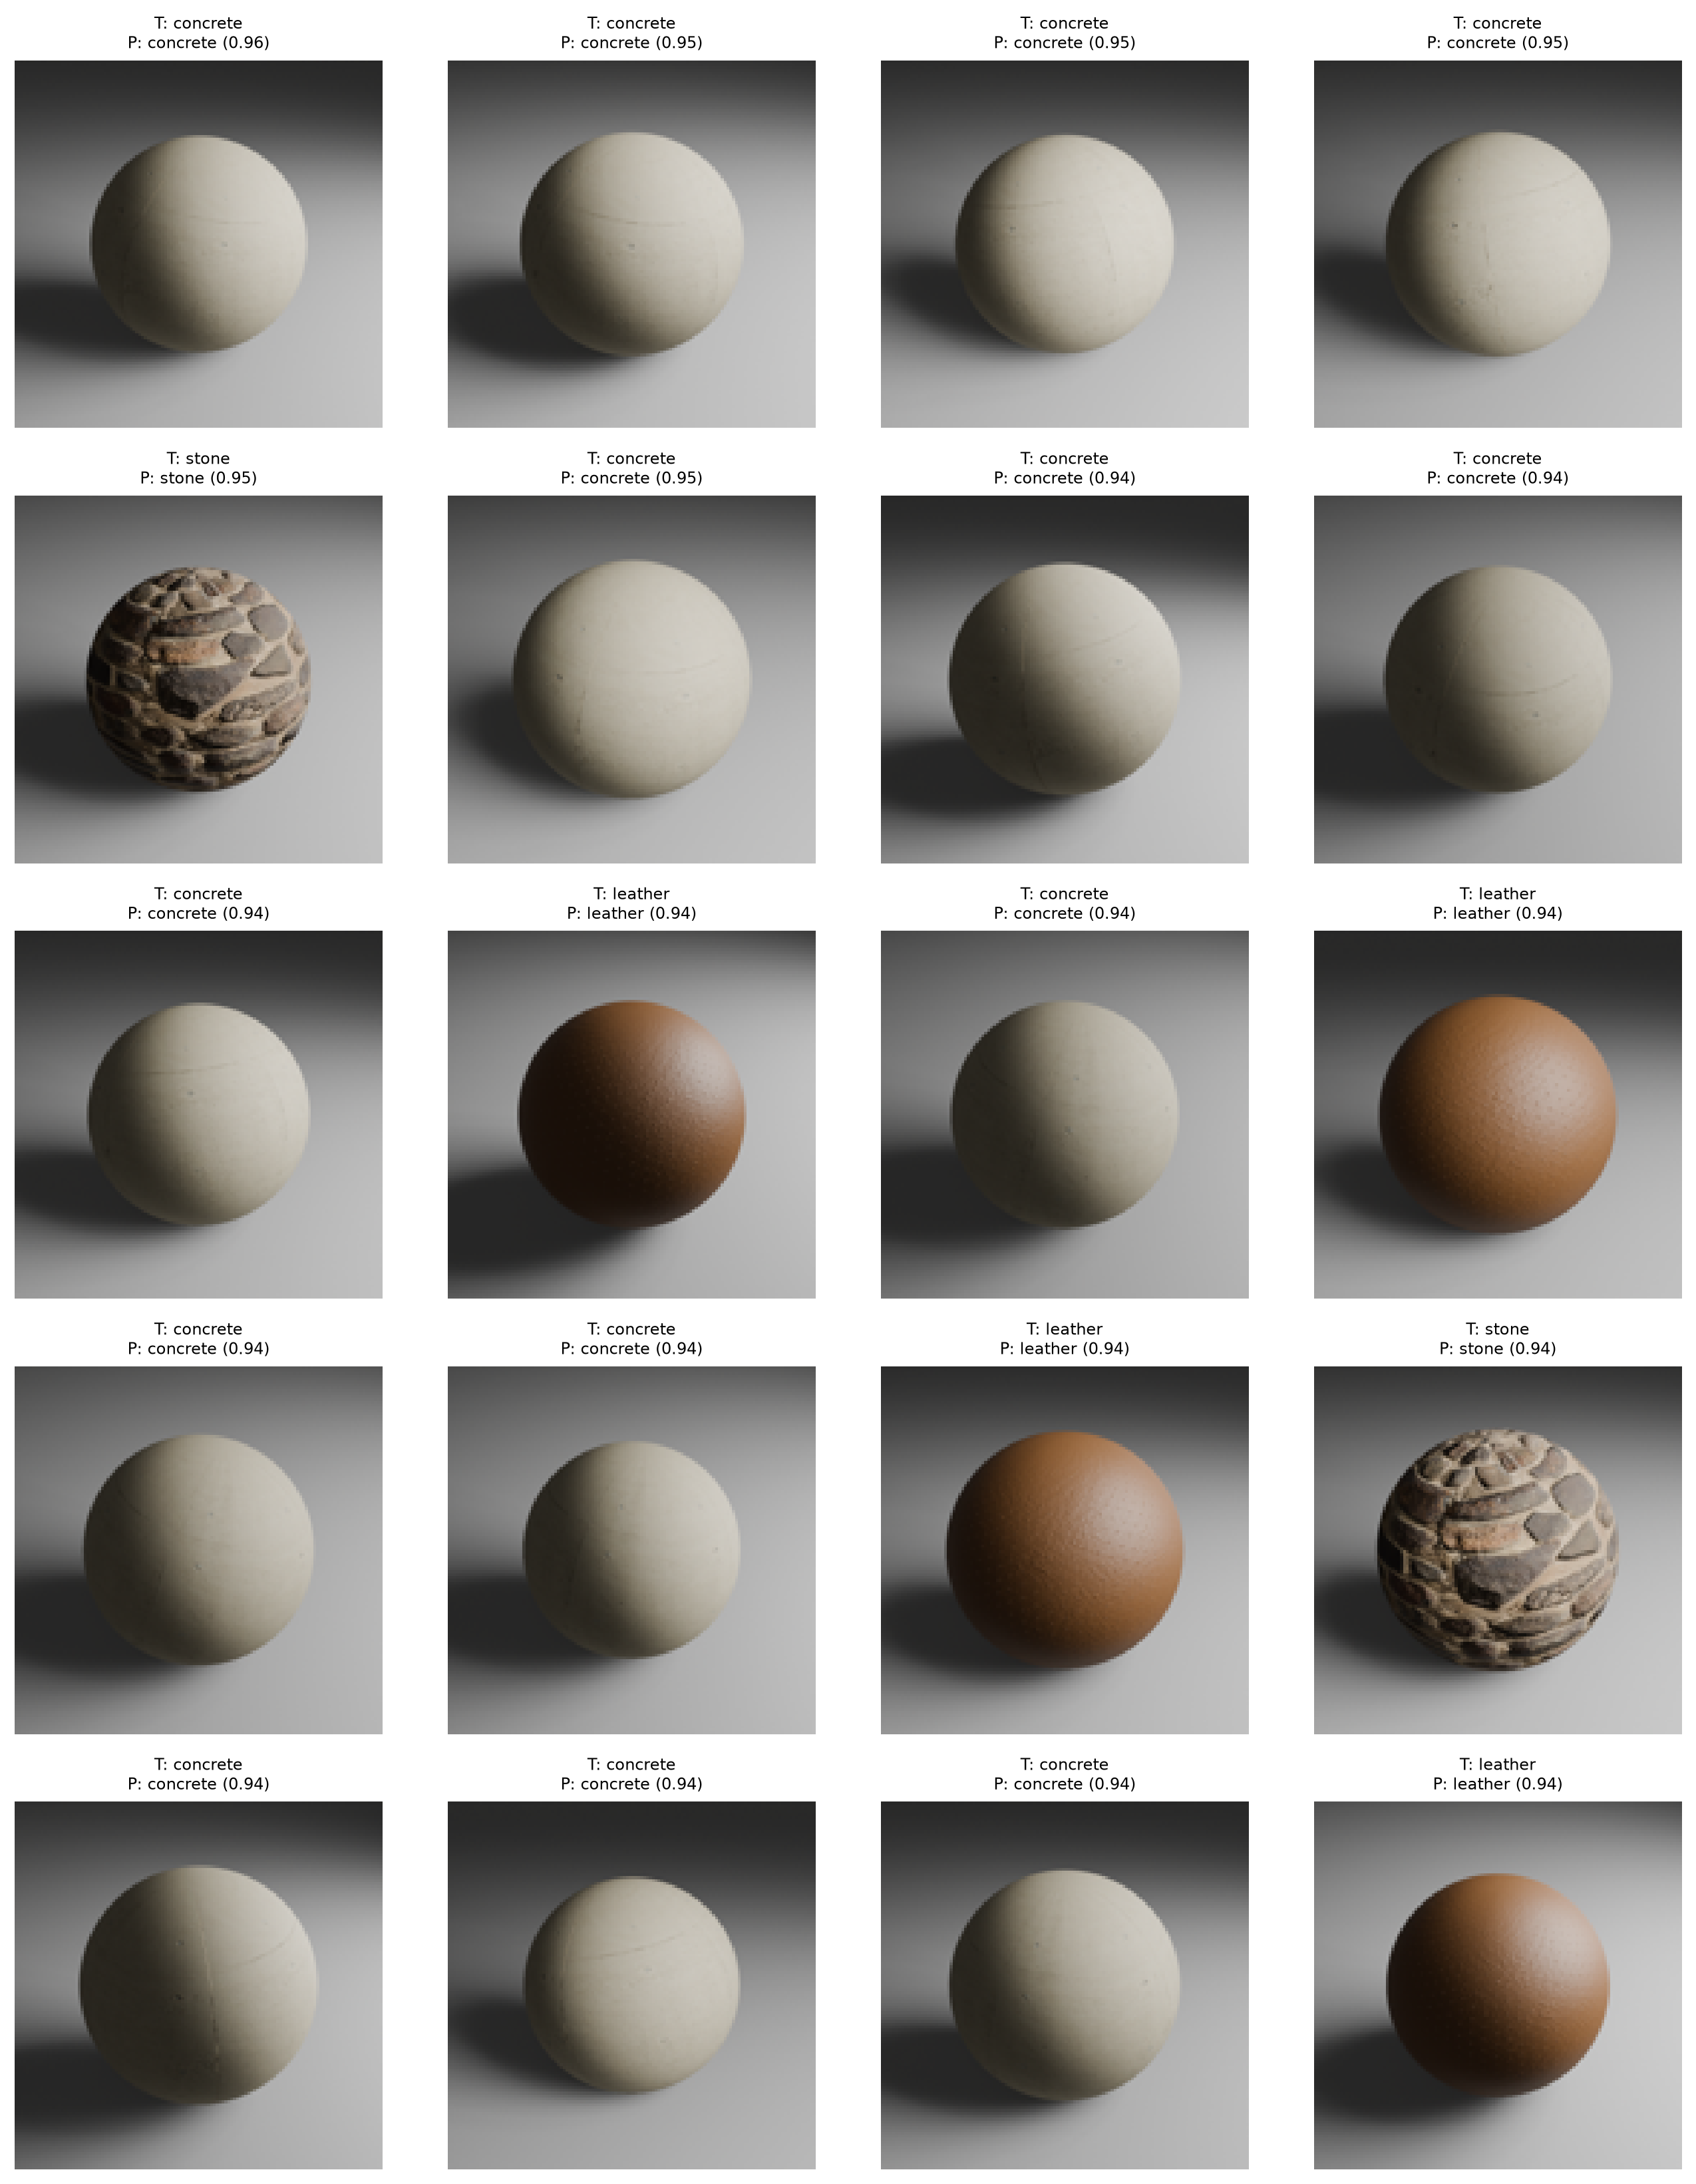

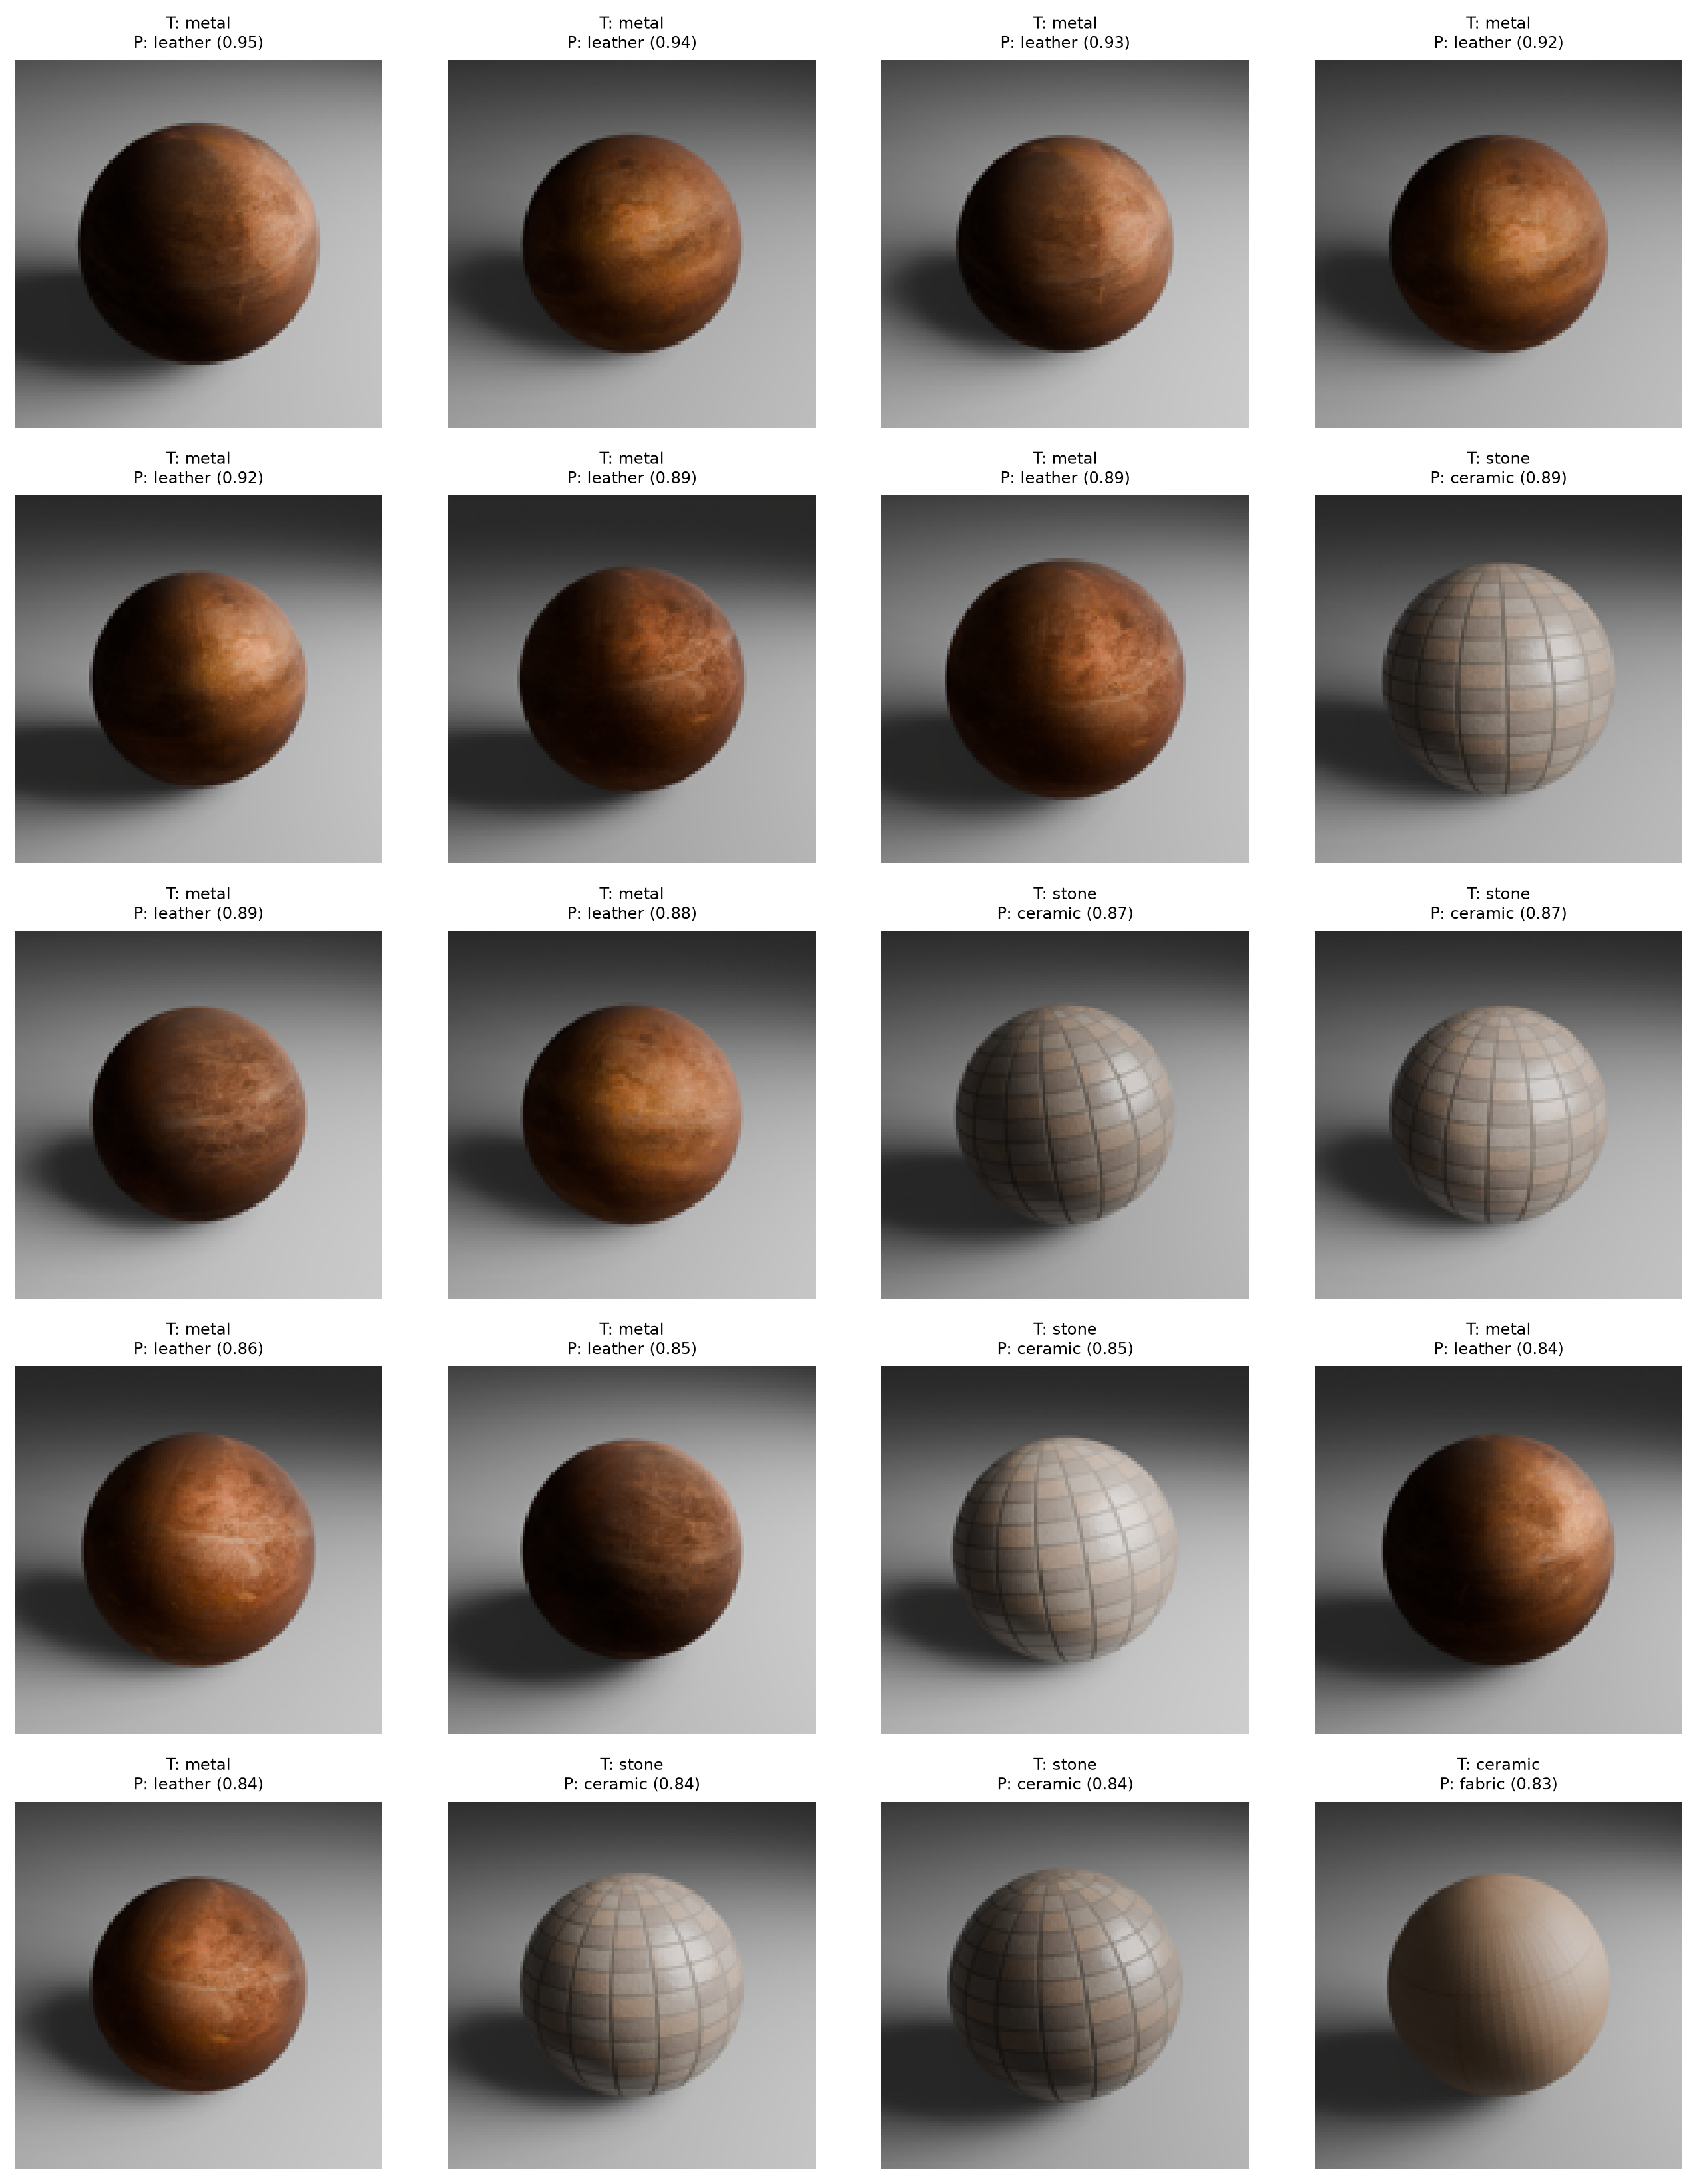

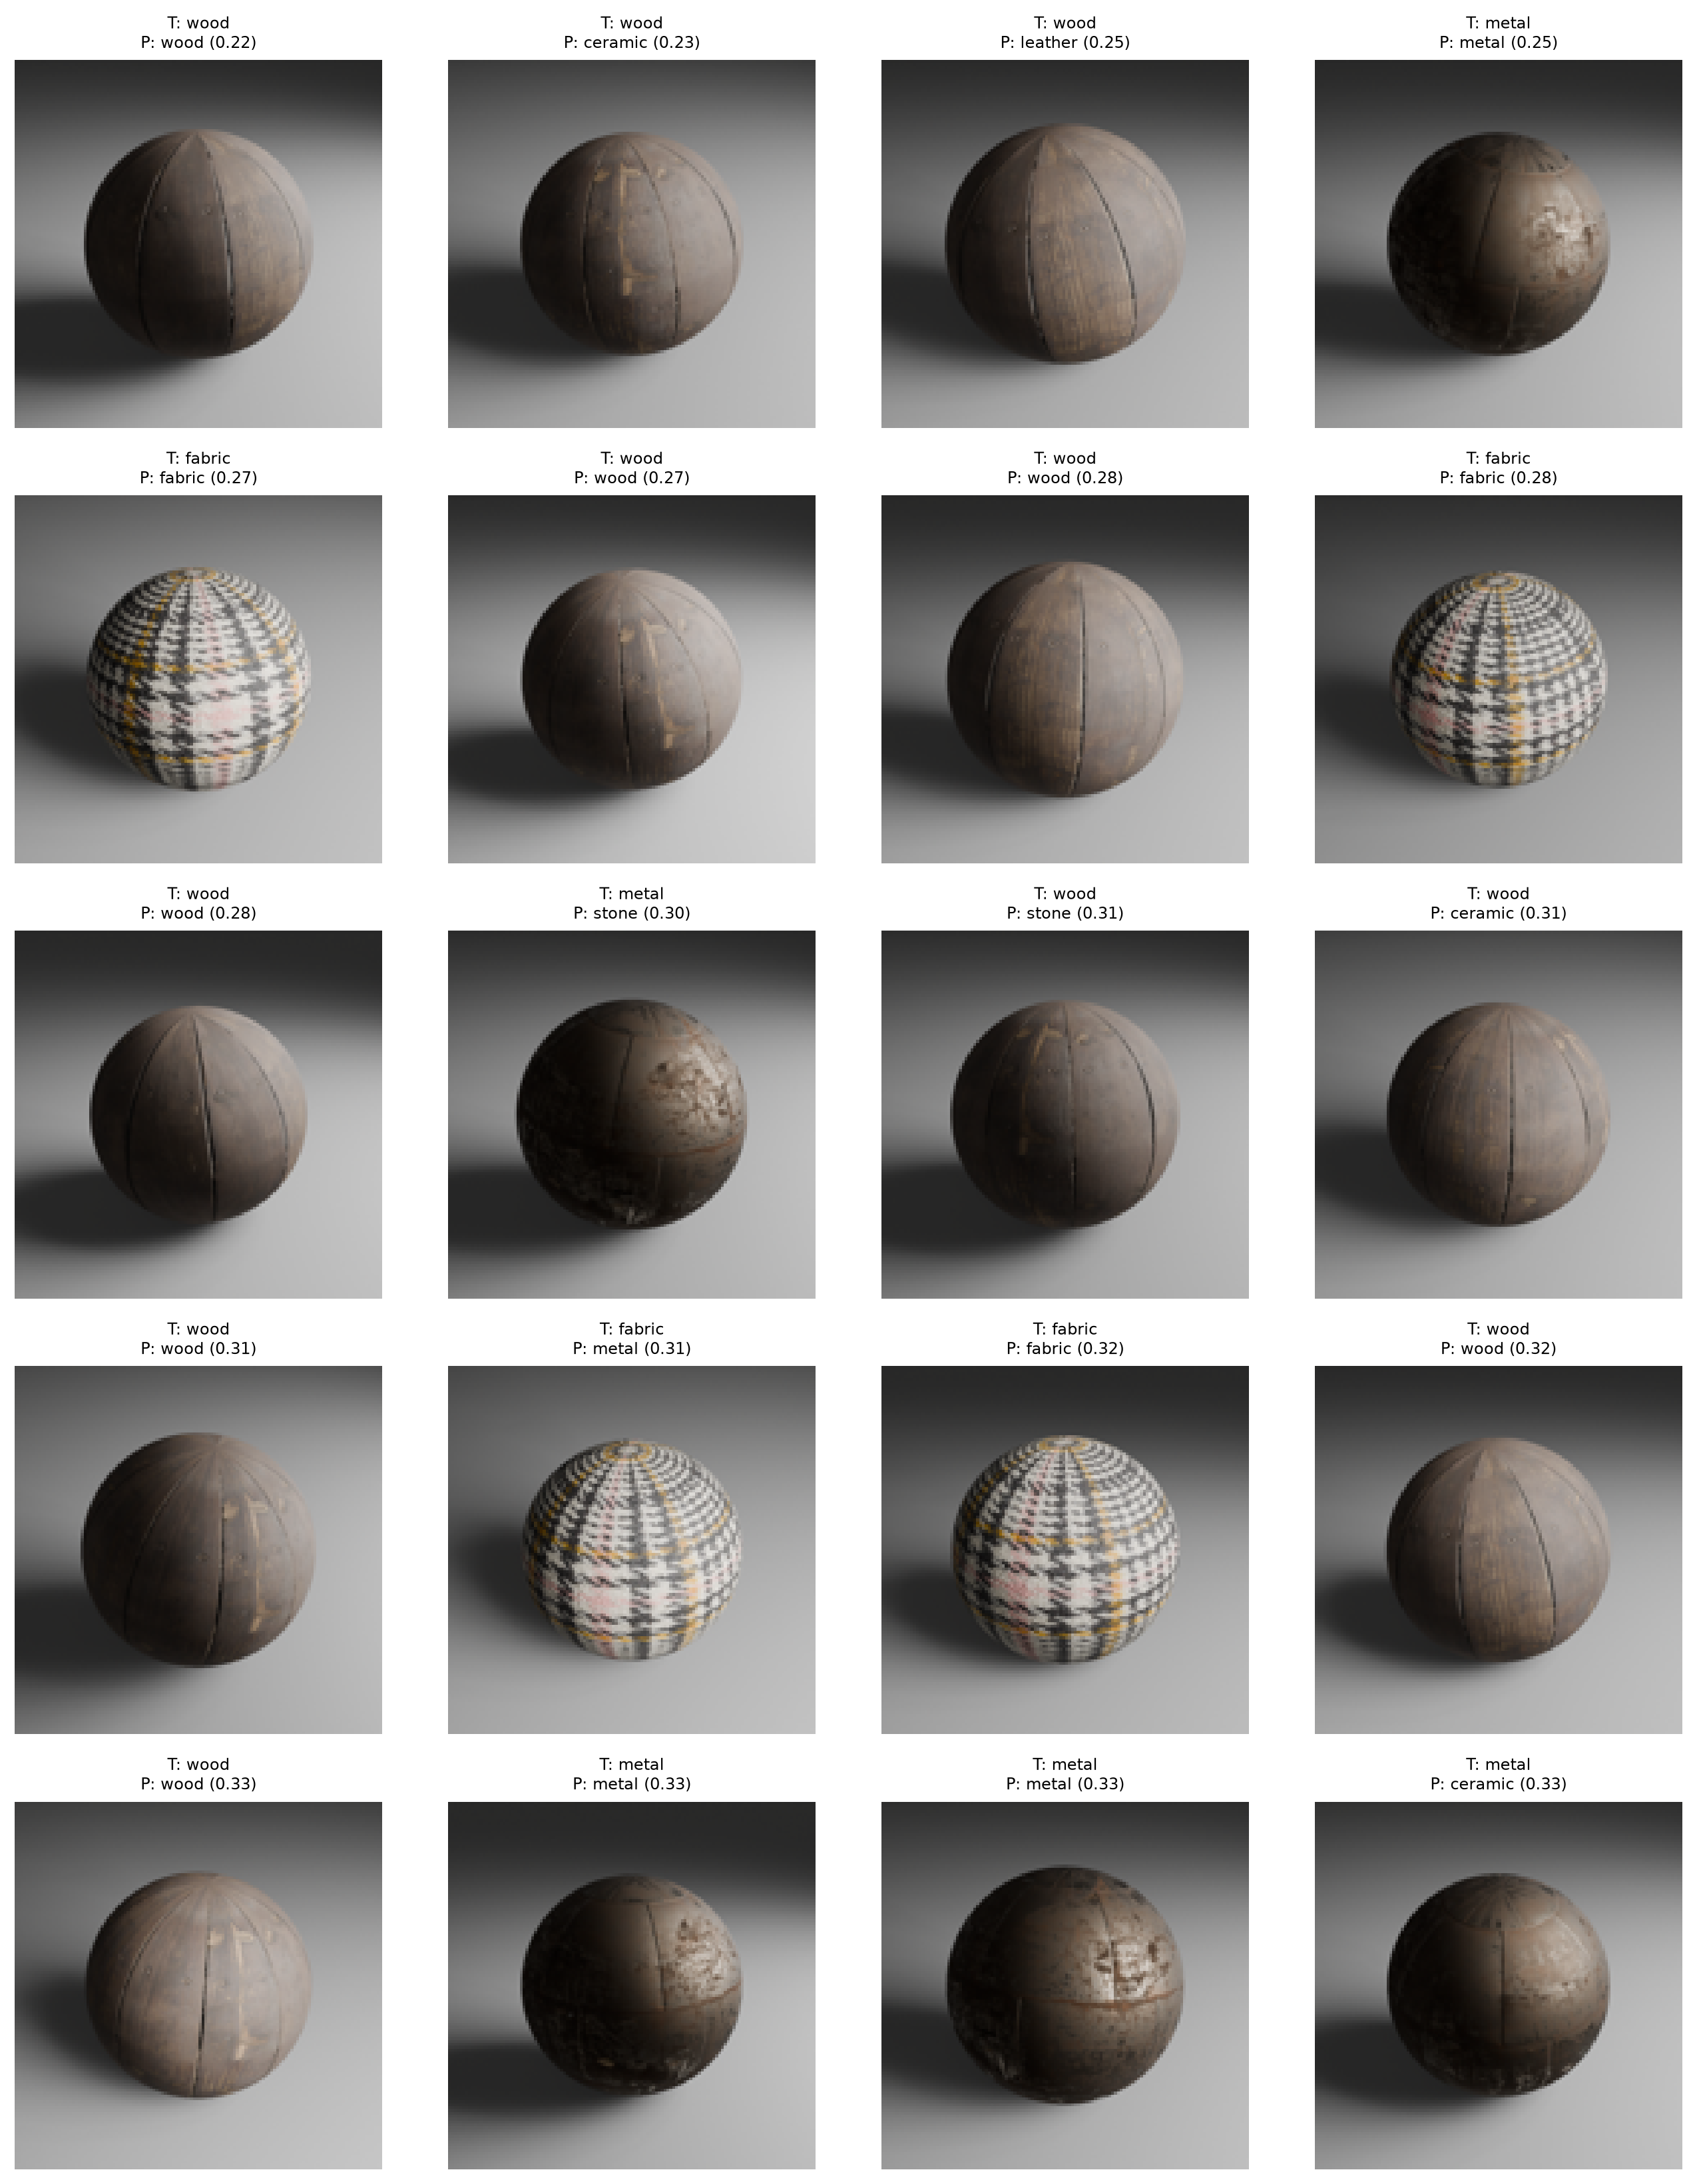

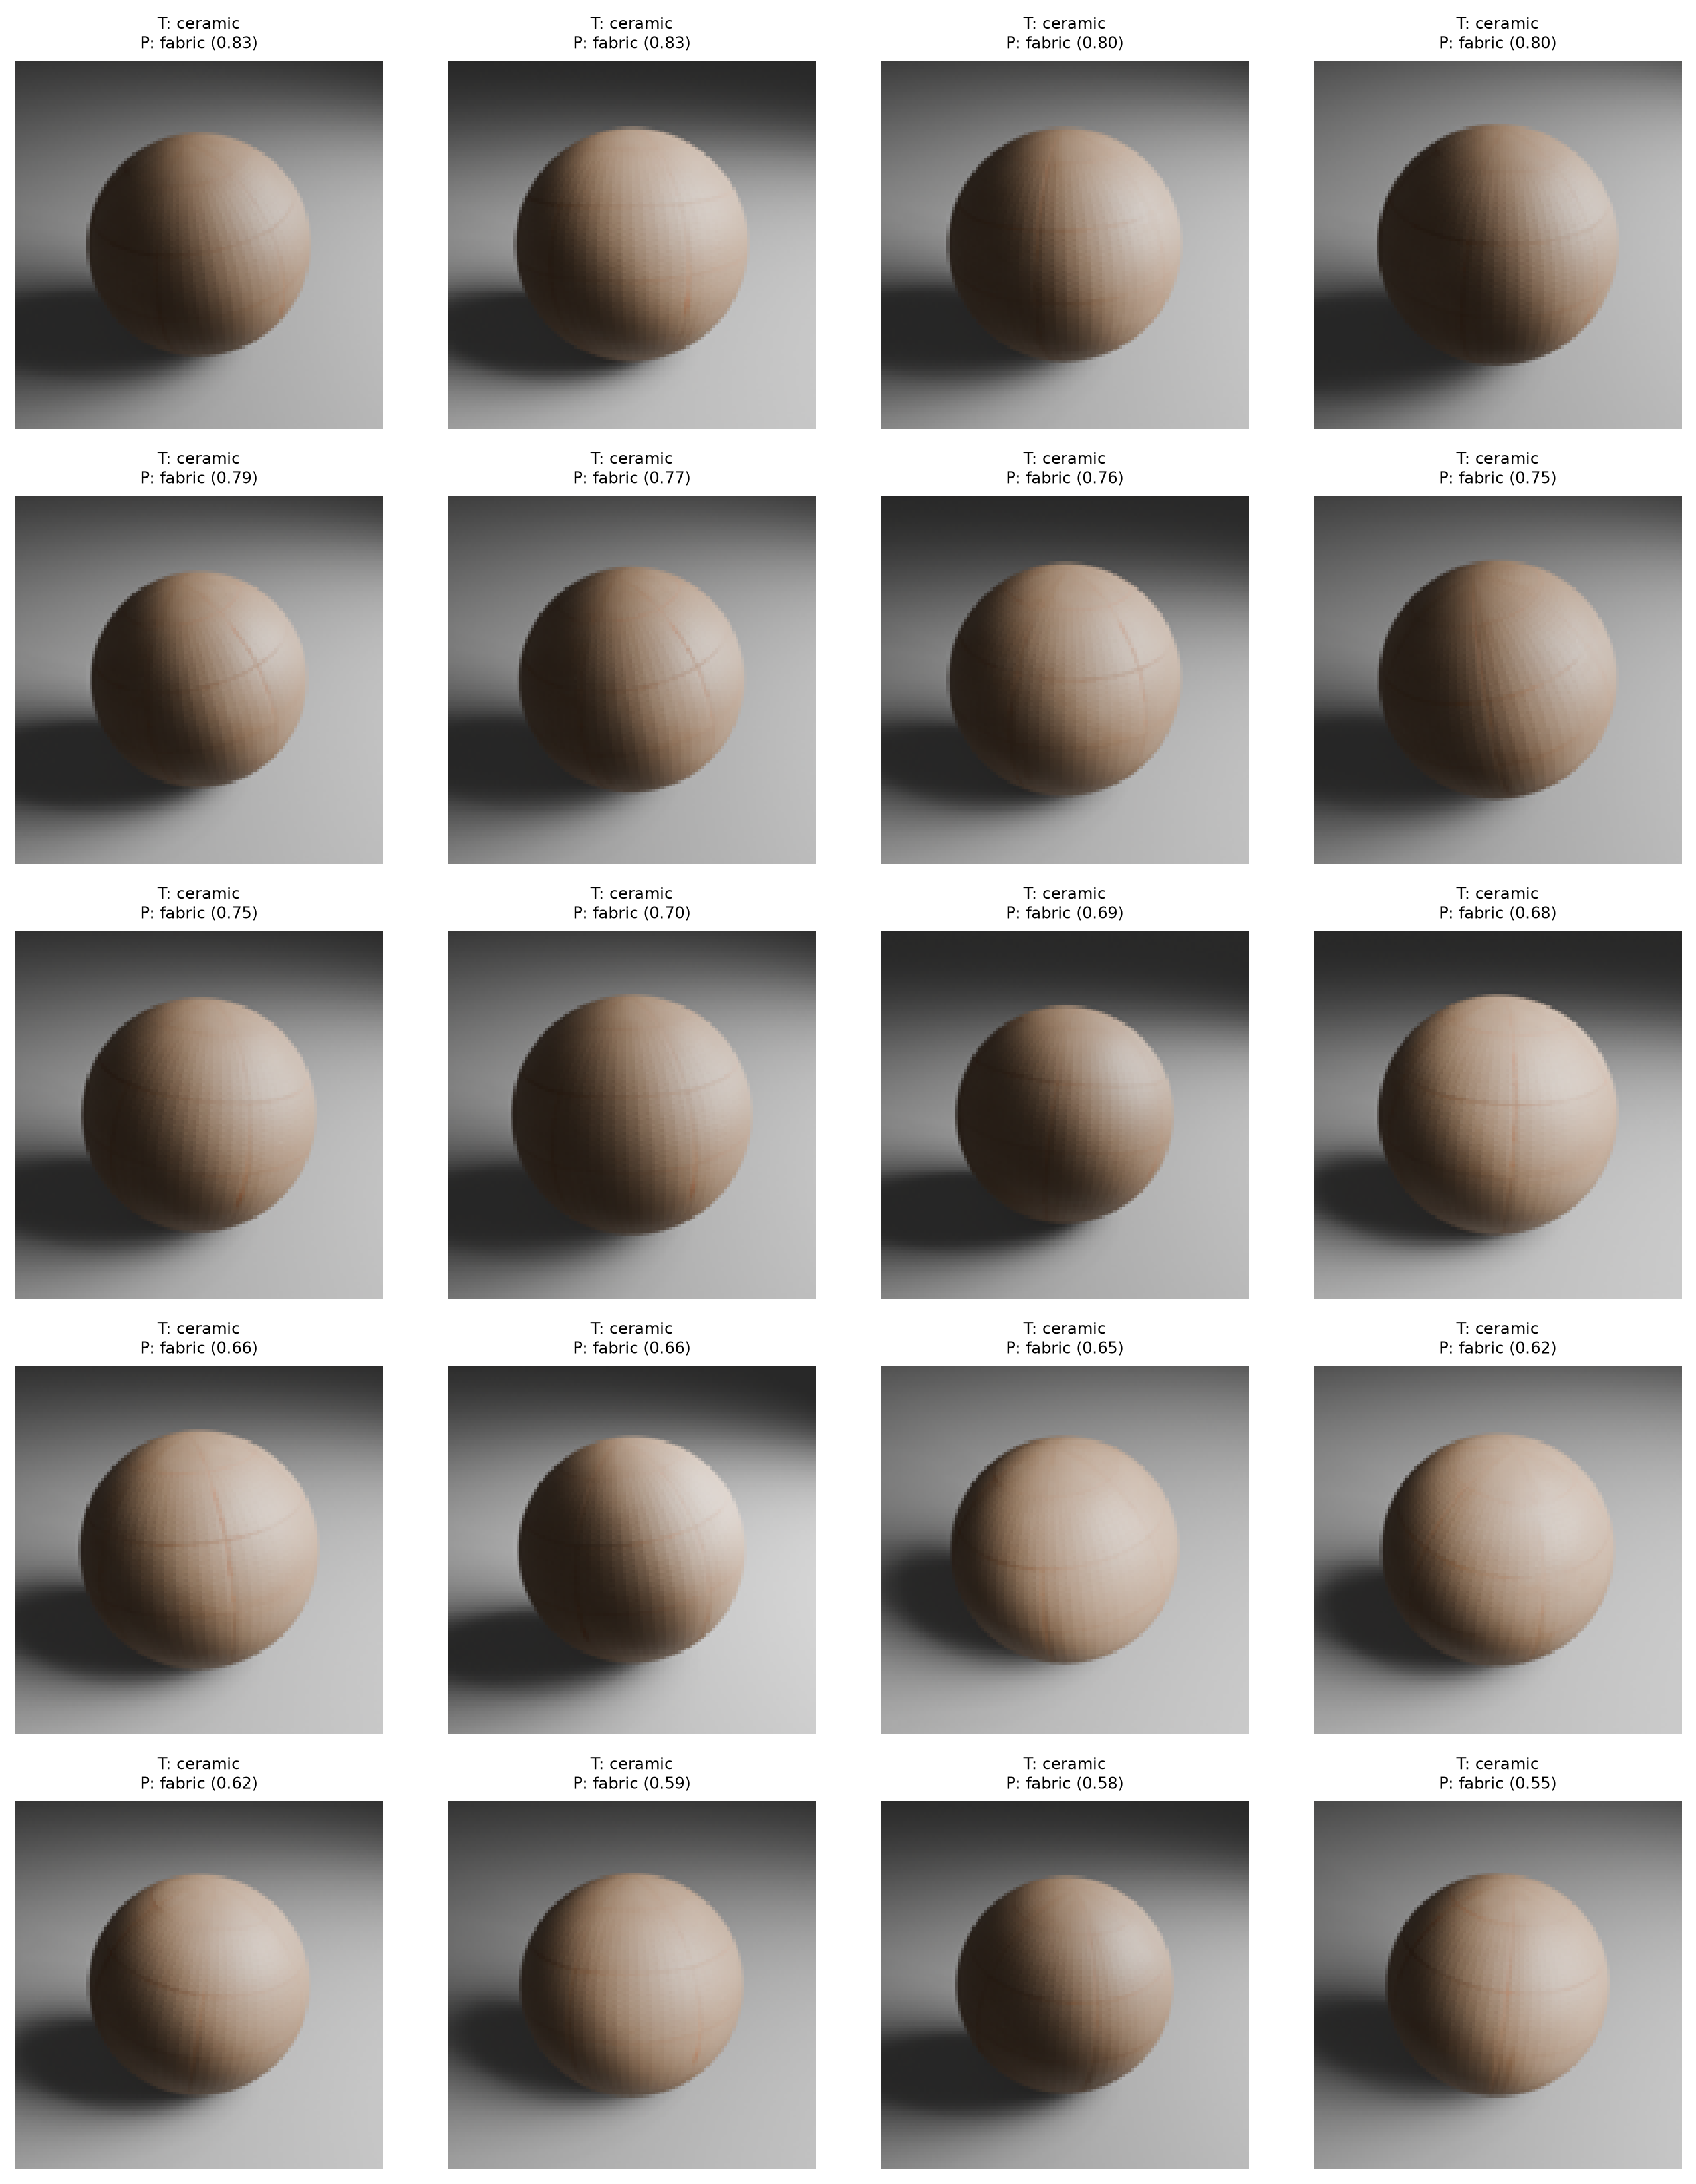

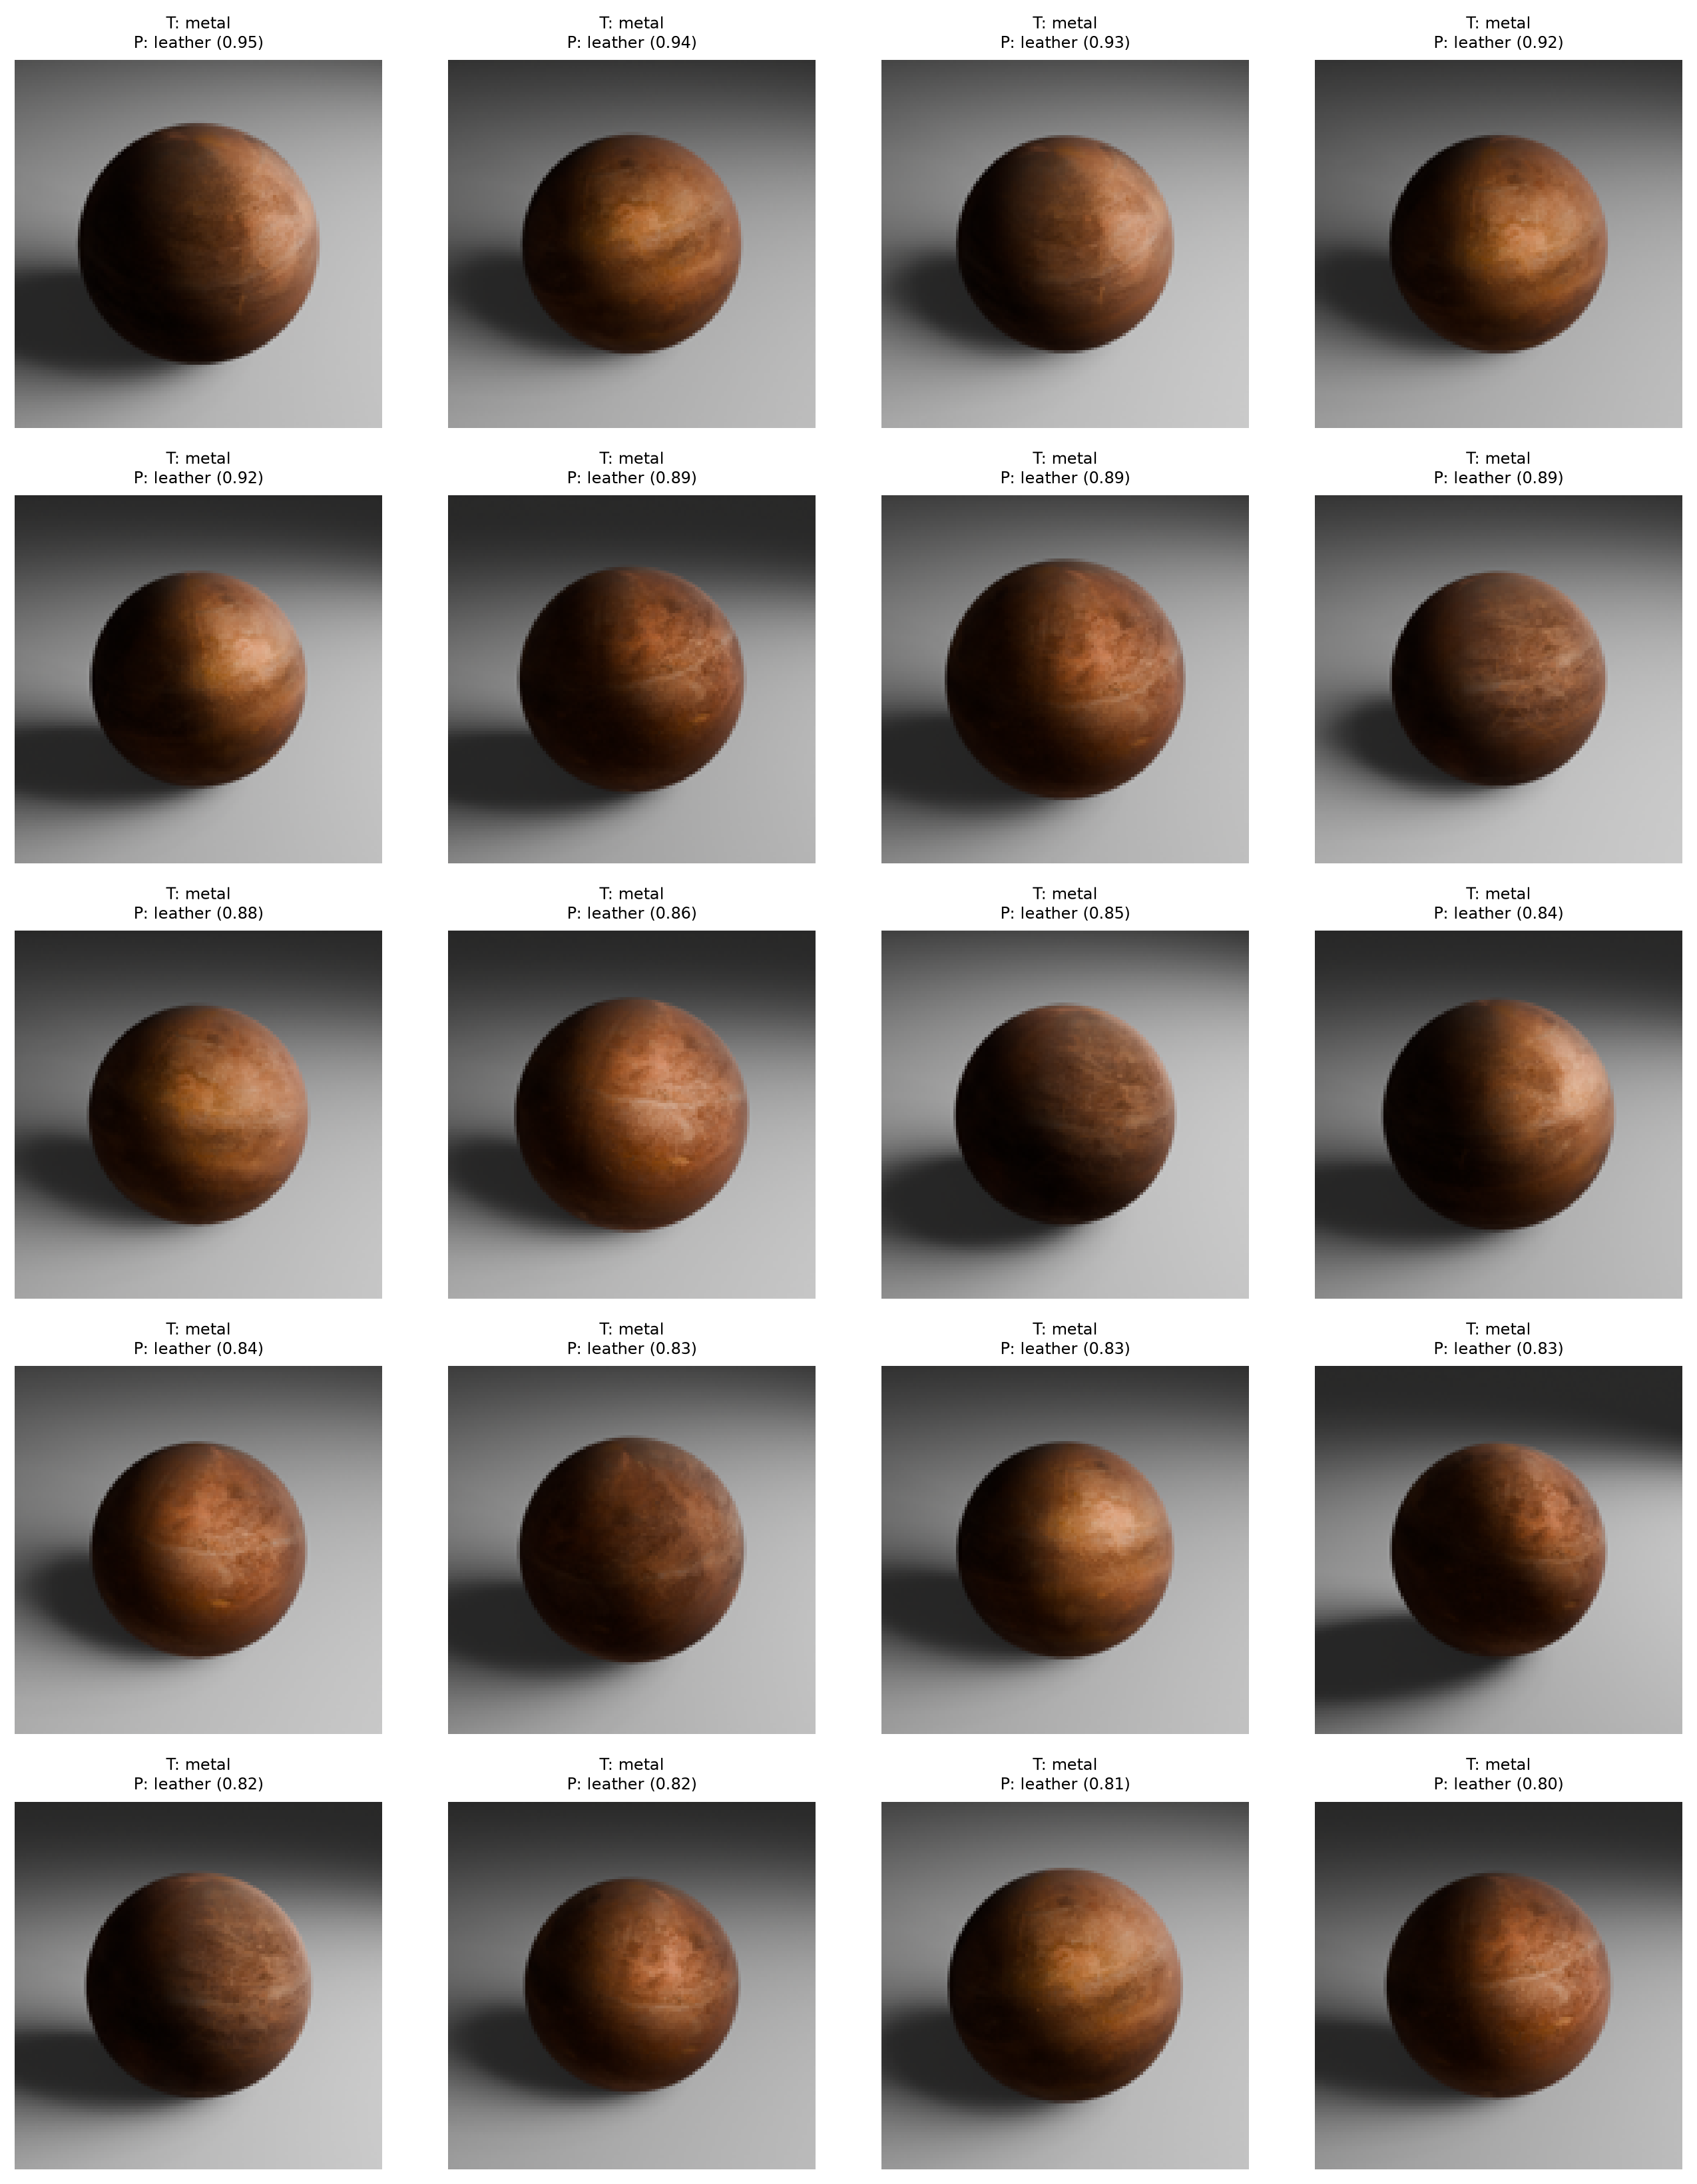

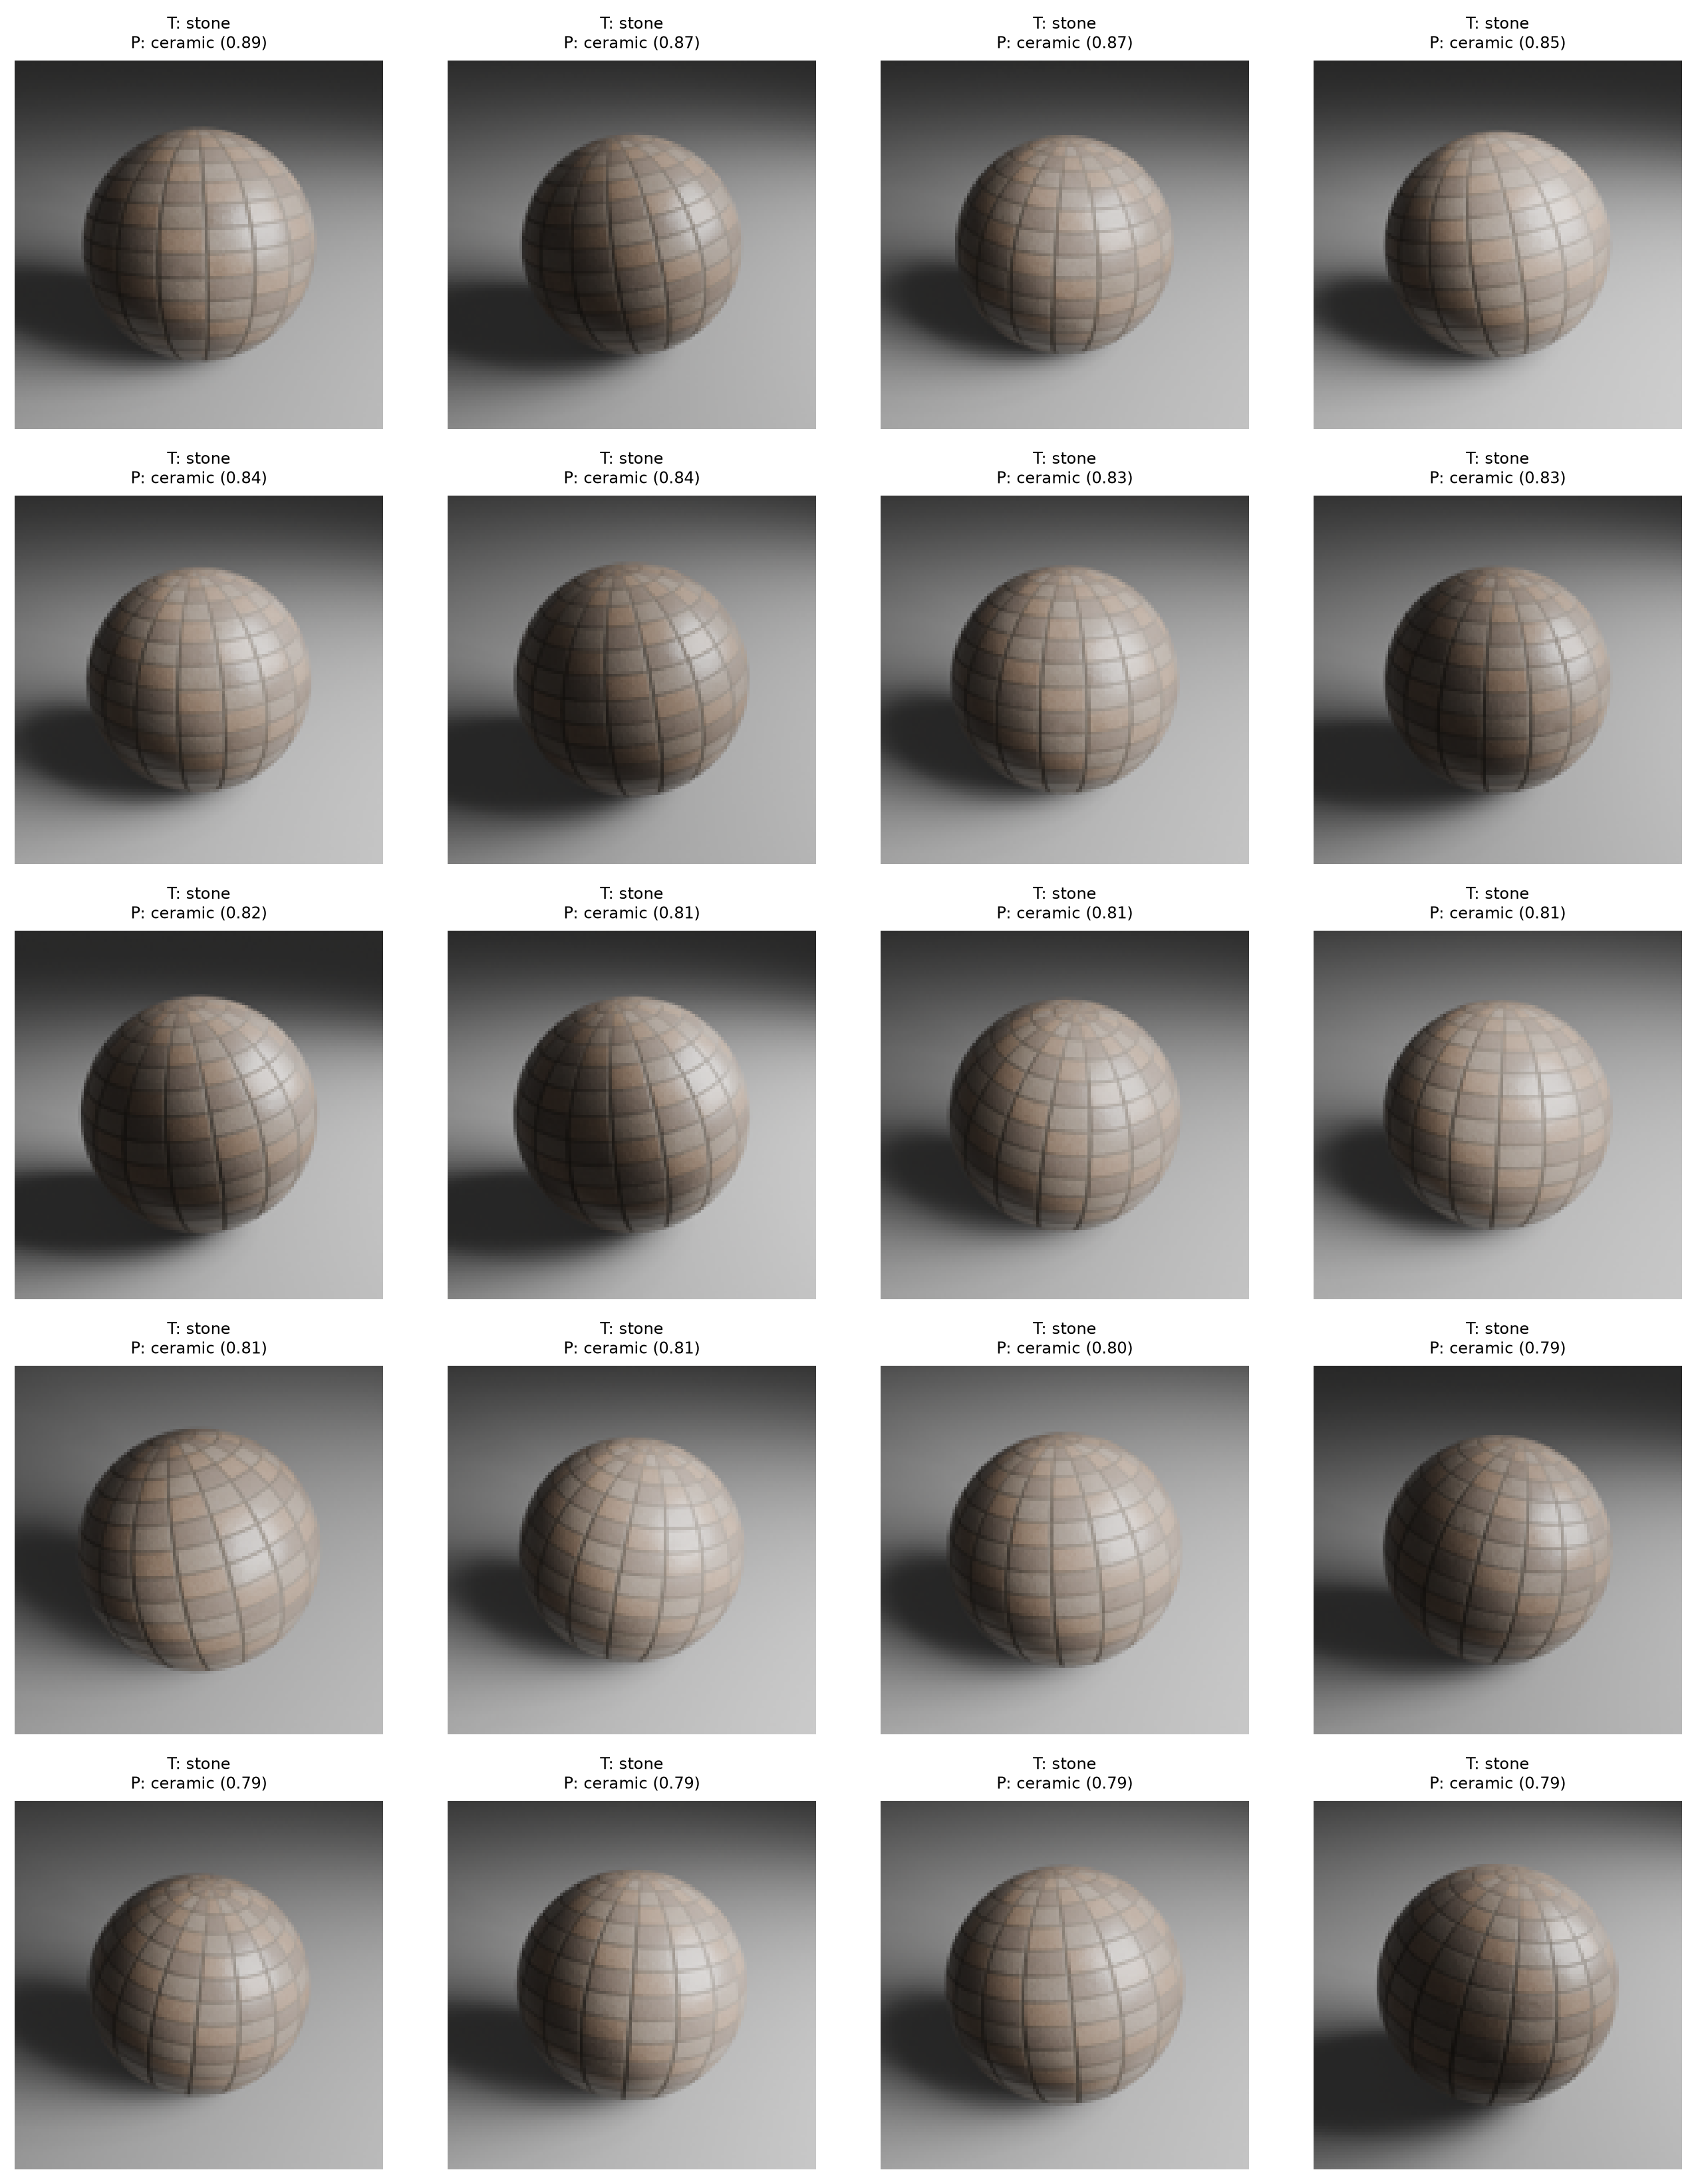

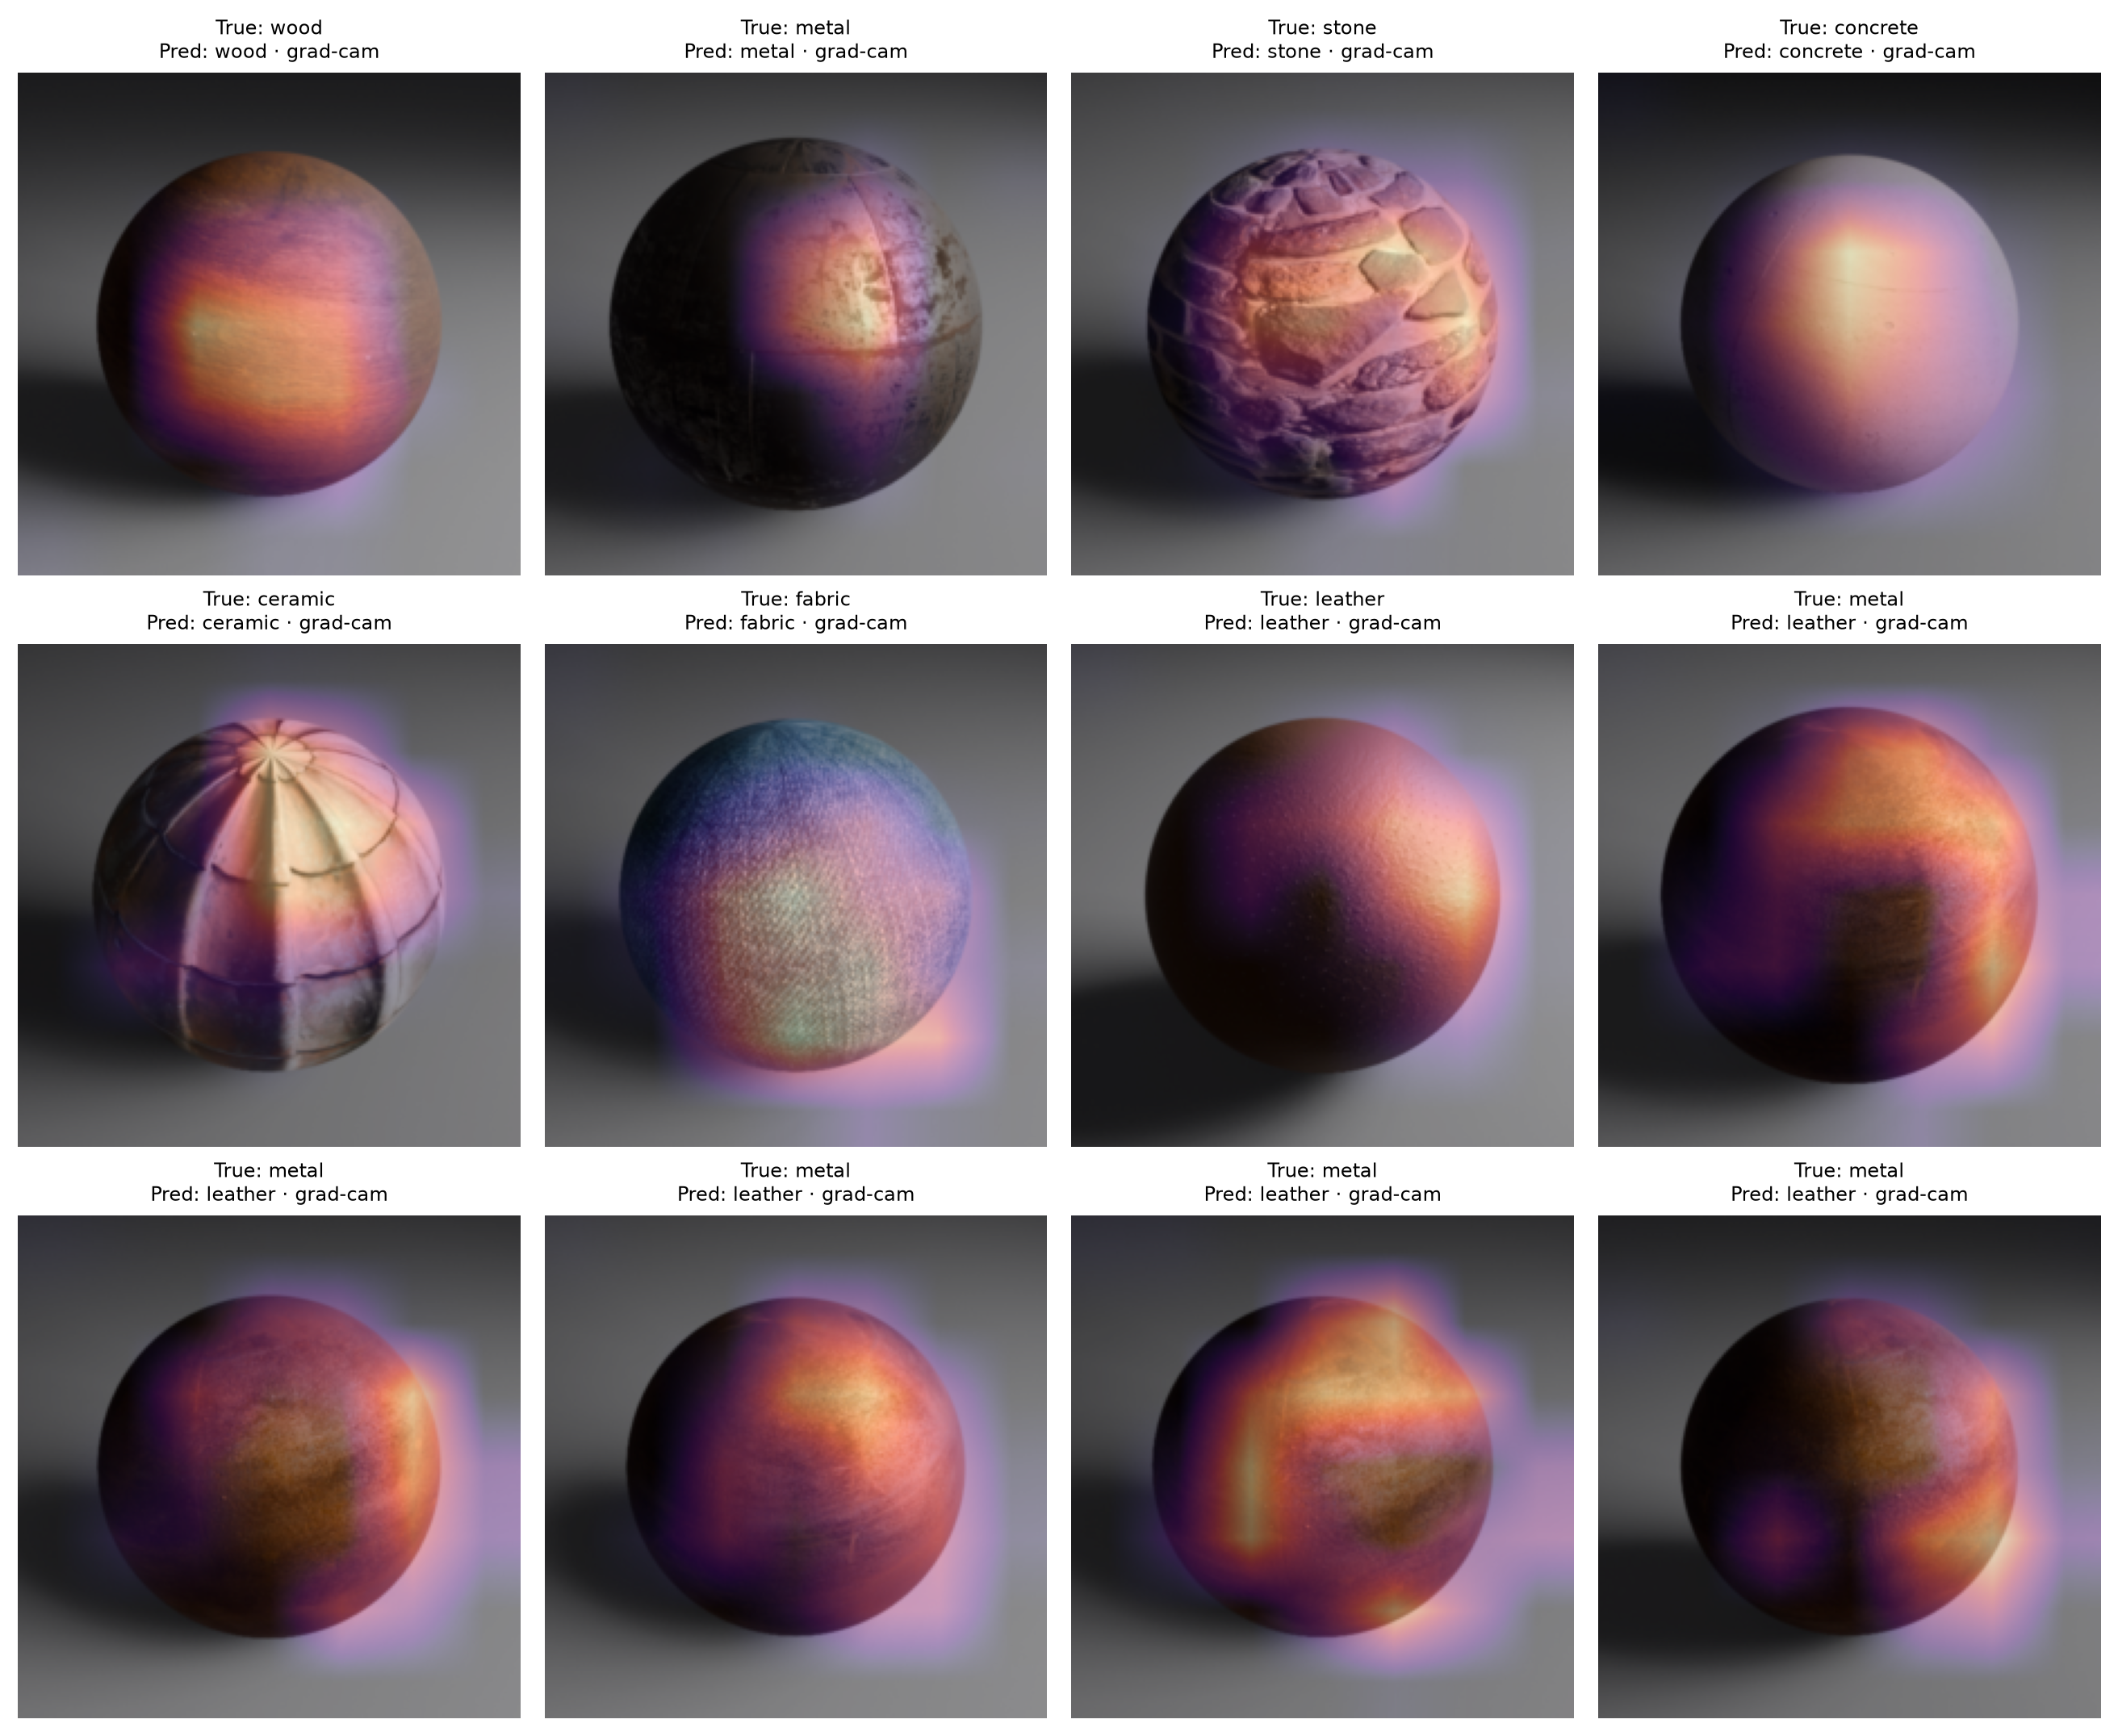

In [4]:
gallery_paths = sorted((ROOT / 'reports' / 'figures' / 'errors').glob(f'{model}_*.png'))
gallery_paths += sorted((ROOT / 'reports' / 'figures' / 'explainability').glob(f'{model}_*.png'))
if gallery_paths:
    for path in gallery_paths: display(Image(filename=str(path), width=900))
else:
    print('No cached error or explainability galleries yet; generate_visuals.py consumes final predictions to create them.')